## Kevin Feracho
## DSC 670
## 9.2 Exercise MLFlow

### DSC 670: Week 9 Exercise

### Monitoring a Generative AI Application with MLflow

### Introduction

So far in this course, I’ve mostly tested models and tweaked how they handle information, always with an eye on the quality of the output. This week shifts the focus to something I haven’t worked with much: tracking how an application behaves once people start using it.

Following the example in our textbook, I’ll build a basic chatbot with Python and OpenAI’s API, then use MLflow to record metrics from the chatbot's interactions. Rather than judging only whether the answers are good, I’ll record how long each response takes, how many tokens it uses, and which settings produced it.

That last part matters more than it might seem. Two requests can return equally useful answers while one takes far longer or burns through many more tokens. Without monitoring, that gap goes unnoticed until it shows up as a slow application or a bigger bill. An application has to be practical to run, not just capable of answering questions.

I plan to document the setup, walk through the code, and review the measurements from the experiment. My goal is to understand how MLflow helps developers evaluate and maintain a generative AI application after the initial build is finished.

### Environment Setup and Library Verification

Before building the chatbot, I checked that my JupyterLab environment had the necessary Python libraries installed. This step helps identify any missing dependencies before I begin working with the OpenAI API and MLflow.

In [1]:
import sys
import mlflow
import openai
import tiktoken
import prometheus_client
import colorama

print("Python version:", sys.version.split()[0])
print("MLflow version:", mlflow.__version__)
print("OpenAI version:", openai.__version__)
print("All libraries imported successfully!")

Python version: 3.11.18
MLflow version: 3.18.0
OpenAI version: 3.46.0
All libraries imported successfully!


### Connecting to the MLflow Tracking Server

After verifying the required libraries, I started the MLflow server locally and opened its dashboard in my browser. The server will allow me to record and review information from the chatbot experiments. I will now connect my notebook to the server and create a separate experiment to keep the results organized.

In [2]:
import mlflow

MLFLOW_URI = "http://127.0.0.1:5000"

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment("DSC_670_Week_9_MLflow")

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment created or selected successfully!")


2026/11/05 19:42:26 INFO mlflow.tracking.fluent: Experiment with name 'DSC_670_Week_9_MLflow' does not exist. Creating a new experiment.


Tracking URI: http://127.0.0.1:5000
Experiment created or selected successfully!


### Configuring the OpenAI Chatbot

With the MLflow experiment created, my next step is to prepare the chatbot. The example from the textbook uses OpenAI's API and several settings that control how responses are generated. I will configure these settings and load my API key securely before testing the application. Keeping the settings consistent will also make it easier to compare the results recorded in MLflow.

In [1]:
import os
import getpass
from openai import OpenAI


API_KEY = os.getenv("OPENAI_API_BOOK_KEY")

if not API_KEY:
    API_KEY = getpass.getpass("Enter your OpenAI API key: ")


client = OpenAI(api_key=API_KEY)


MODEL = "gpt-4o-mini"
TEMPERATURE = 0.7
TOP_P = 1
FREQUENCY_PENALTY = 0
PRESENCE_PENALTY = 0
MAX_TOKENS = 800

print("OpenAI client initialized successfully!")
print("Selected model:", MODEL)
print("Maximum response tokens:", MAX_TOKENS)


Enter your OpenAI API key:  ········


OpenAI client initialized successfully!
Selected model: gpt-4o-mini
Maximum response tokens: 800


### Counting Tokens with Tiktoken

Before testing the chatbot, I need a way to measure token usage. OpenAI models process text as tokens rather than individual words, so counting them gives me a better idea of how much information is being sent and generated. The textbook example uses the Tiktoken library for this purpose. I will create a function that counts tokens so I can include those measurements in my MLflow experiment.

In [2]:
import tiktoken

def count_tokens(text, encoding_name="cl100k_base"):
    encoding = tiktoken.get_encoding(encoding_name)
    encoded_text = encoding.encode(text, disallowed_special=())
    return len(encoded_text)

sample_text = "I am learning how to monitor generative AI applications using MLflow."

token_count = count_tokens(sample_text)

print("Sample text:", sample_text)
print("Token count:", token_count)


Sample text: I am learning how to monitor generative AI applications using MLflow.
Token count: 14


### Generating Responses and Recording Metrics

Now that the token-counting function works, I will connect the chatbot to MLflow. The next function will send a conversation to OpenAI, measure how long the response takes, and record the token usage and model settings. I want to see how these measurements appear in MLflow and whether they can help me understand the application's performance.

In [3]:
import time
import mlflow

def generate_text(conversation, max_tokens=100):
    start_time = time.perf_counter()

    response = client.chat.completions.create(
        model=MODEL,
        messages=conversation,
        temperature=TEMPERATURE,
        max_tokens=max_tokens,
        top_p=TOP_P,
        frequency_penalty=FREQUENCY_PENALTY,
        presence_penalty=PRESENCE_PENALTY
    )

    latency = time.perf_counter() - start_time
    message_response = response.choices[0].message.content or ""

    prompt_tokens = response.usage.prompt_tokens
    completion_tokens = response.usage.completion_tokens
    total_tokens = response.usage.total_tokens

    with mlflow.start_run(run_name="Chatbot_Request"):
        mlflow.log_params({
            "model": MODEL,
            "temperature": TEMPERATURE,
            "top_p": TOP_P,
            "frequency_penalty": FREQUENCY_PENALTY,
            "presence_penalty": PRESENCE_PENALTY,
            "max_tokens": max_tokens
        })

        mlflow.log_metrics({
            "request_count": 1,
            "request_latency": latency,
            "prompt_tokens": prompt_tokens,
            "completion_tokens": completion_tokens,
            "conversation_tokens": total_tokens
        })

    return message_response


### Testing the Chatbot

With the response-generation function ready, I will send a test message to the chatbot and check whether it returns a response. I will also examine the MLflow dashboard to confirm that the request's response time, token usage, and model settings were recorded. This will help me verify that the chatbot and monitoring system are working together.

In [4]:
conversation = [
    {"role": "system", "content": "You are a helpful assistant."},
    {"role": "user", "content": "Explain MLflow in simple terms."}
]

ai_output = generate_text(conversation, MAX_TOKENS)

print("User:", conversation[-1]["content"])
print("AI Assistant:", ai_output)

conversation.append({
    "role": "assistant",
    "content": ai_output
})


2026/11/05 20:09:59 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/05 20:09:59 INFO mlflow.store.db.utils: Updating database tables
2026/11/05 20:10:02 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a rais

User: Explain MLflow in simple terms.
AI Assistant: MLflow is an open-source platform designed to manage the machine learning (ML) lifecycle, which includes everything from experimentation to deployment. Think of it as a toolkit that helps data scientists and machine learning engineers keep track of their work and make it easier to build, deploy, and maintain ML models.

Here's a breakdown of its main components in simple terms:

1. **Tracking**: MLflow allows you to log and track your experiments. When you try out different models or parameters, you can record the results, such as accuracy, loss, and other metrics, so you can compare them later.

2. **Projects**: MLflow helps you organize your code and experiments into reproducible projects. This means that you can package your model code and dependencies in a way that makes it easy for others (or yourself in the future) to run the same experiments.

3. **Models**: Once you've trained a model, MLflow lets you save it in a standard for

In [5]:
import mlflow

print("Tracking URI:", mlflow.get_tracking_uri())

experiment = mlflow.get_experiment_by_name("DSC_670_Week_9_MLflow")

print("Experiment ID:", experiment.experiment_id if experiment else "Not found")

if experiment:
    runs = mlflow.search_runs(
        experiment_ids=[experiment.experiment_id],
        run_view_type=mlflow.entities.ViewType.ALL
    )
    print("Recorded runs:", len(runs))

    if not runs.empty:
        display(runs[["run_id", "status", "tags.mlflow.runName"]])


Tracking URI: sqlite:///C%3A/Users/kevin/OneDrive/School/Classes/Fall 2026/DSC 670/mlflow.db
Experiment ID: Not found


In [6]:
import mlflow

MLFLOW_URI = "http://127.0.0.1:5000"

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment("DSC_670_Week_9_MLflow")

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", mlflow.active_run())

Tracking URI: http://127.0.0.1:5000
Experiment: None


In [7]:
local_uri = "sqlite:///C%3A/Users/kevin/OneDrive/School/Classes/Fall 2026/DSC 670/mlflow.db"

local_client = mlflow.tracking.MlflowClient(tracking_uri=local_uri)

for experiment in local_client.search_experiments():
    print("Experiment:", experiment.name)

    runs = local_client.search_runs([experiment.experiment_id])

    for run in runs:
        print("Run:", run.info.run_name)
        print("Metrics:", run.data.metrics)

Experiment: Default
Run: Chatbot_Request
Metrics: {'request_count': 1.0, 'request_latency': 4.546838899987051, 'prompt_tokens': 24.0, 'completion_tokens': 302.0, 'conversation_tokens': 326.0}


In [8]:
import mlflow

print("Tracking URI:", mlflow.get_tracking_uri())

experiment = mlflow.get_experiment_by_name("DSC_670_Week_9_MLflow")

print("Experiment name:", experiment.name if experiment else "Not found")
print("Experiment ID:", experiment.experiment_id if experiment else "Not found")


Tracking URI: http://127.0.0.1:5000
Experiment name: DSC_670_Week_9_MLflow
Experiment ID: 1


### Troubleshooting the MLflow Tracking Connection

During my first chatbot test, the OpenAI request completed successfully, but I couldn't find the recorded metrics in the MLflow dashboard. After checking the tracking URI, I discovered that the notebook was using a local SQLite database instead of the MLflow server I had started earlier.

I checked the local database and found the original run, including its response time and token usage. This helped me understand why confirming the tracking location is important. The chatbot can work correctly while its monitoring data is stored somewhere other than where I expected. I updated the tracking connection so future experiments would be recorded in the intended location.

### Comparing Chatbot Requests

Now that I have confirmed where MLflow is recording the results, I want to compare how the chatbot handles different requests. I will use three prompts that vary in complexity and examine the response time and token usage for each one.

I am interested in whether a more detailed question requires more tokens or takes longer to answer. These measurements will not tell me whether the responses are accurate, but they should help me understand how the application's workload changes between requests.

In [9]:
import mlflow

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("DSC_670_Week_9_MLflow")

test_prompts = [
    "What is machine learning?",
    "Explain the difference between supervised and unsupervised learning.",
    "Explain how a business could use machine learning to predict customer churn, including the data needed and possible challenges."
]

for i, prompt in enumerate(test_prompts, start=1):
    conversation = [
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": prompt}
    ]

    print(f"\nTEST {i}")
    print("User:", prompt)

    response = generate_text(conversation, MAX_TOKENS)

    print("AI Assistant:", response)
    print("-" * 60)


TEST 1
User: What is machine learning?
🏃 View run Chatbot_Request at: http://127.0.0.1:5000/#/experiments/1/runs/20b72939e9a0436083d71dd4689e5561
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
AI Assistant: Machine learning is a subset of artificial intelligence (AI) that focuses on the development of algorithms and statistical models that enable computers to perform tasks without explicit programming for each specific task. Instead, machine learning allows systems to learn from and make predictions or decisions based on data.

The core idea behind machine learning is that systems can improve their performance on a specific task over time by analyzing and learning from data. This involves identifying patterns, making inferences, and adapting to new information.

Machine learning can be categorized into several types:

1. **Supervised Learning**: In this approach, the model is trained on a labeled dataset, meaning that each training example is paired with an output label. 

In [10]:
import mlflow
import pandas as pd

mlflow.set_tracking_uri("http://127.0.0.1:5000")

experiment = mlflow.get_experiment_by_name("DSC_670_Week_9_MLflow")

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

results = runs[
    [
        "start_time",
        "metrics.request_latency",
        "metrics.prompt_tokens",
        "metrics.completion_tokens",
        "metrics.conversation_tokens",
        "params.model"
    ]
].copy()

results = results.sort_values("start_time").reset_index(drop=True)

results.insert(0, "Test", ["Test 1", "Test 2", "Test 3"])

results = results.rename(columns={
    "metrics.request_latency": "Response Time (seconds)",
    "metrics.prompt_tokens": "Prompt Tokens",
    "metrics.completion_tokens": "Completion Tokens",
    "metrics.conversation_tokens": "Total Tokens",
    "params.model": "Model"
})

display(results.drop(columns=["start_time"]))


,Test,Response Time (seconds),Prompt Tokens,Completion Tokens,Total Tokens,Model
0,Test 1,5.663649,22.0,382.0,404.0,gpt-4o-mini
1,Test 2,5.521508,28.0,489.0,517.0,gpt-4o-mini
2,Test 3,9.455196,38.0,800.0,838.0,gpt-4o-mini


### Interpreting the Experiment Results

The three tests gave me a better picture of how the chatbot behaves when the requests change. The first question took about 5.66 seconds and used 404 tokens, while the second finished slightly faster at 5.52 seconds despite using 517 tokens. I found that interesting because I initially expected the request using more tokens to take longer.

The third test was noticeably different. It took approximately 9.46 seconds and used 838 tokens. Of those, 800 were generated in the response, which matched the maximum output setting I configured earlier. This raised a question about whether the chatbot had enough room to finish its explanation.

These results showed me why monitoring an application involves more than checking whether it produces an answer. MLflow helped me identify differences in response time and token usage that I might not have noticed otherwise. At the same time, three requests are not enough to establish a reliable pattern, especially since network conditions and the length of each response can affect the measurements.

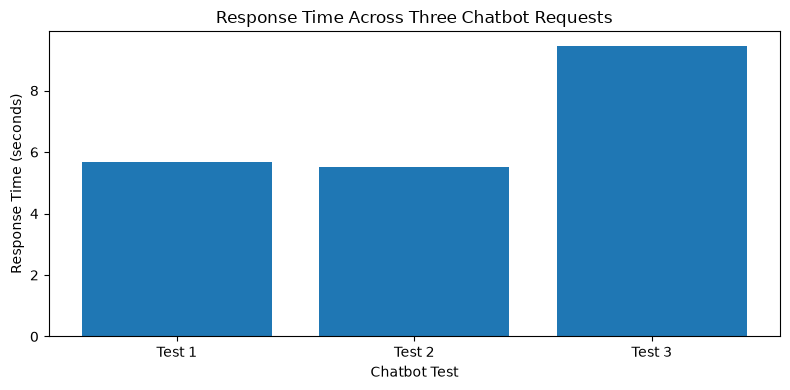

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.bar(
    results["Test"],
    results["Response Time (seconds)"]
)

plt.xlabel("Chatbot Test")
plt.ylabel("Response Time (seconds)")
plt.title("Response Time Across Three Chatbot Requests")
plt.tight_layout()
plt.show()


### Building an Interactive Chatbot

The earlier tests helped me compare response times and token usage across three different questions. Now I want to see how the application works when I enter questions myself instead of having them already written into the code.

The textbook example uses a loop that allows the user to continue chatting until they choose to exit. I will use the same approach while keeping the MLflow tracking function I created earlier. This will let me test the chatbot through an actual conversation and see how each new request is recorded.

In [13]:
conversation = [
    {"role": "system", "content": "You are a helpful assistant."}
]

print("Chatbot is ready!")
print("Type 'exit' to end the conversation.")

while True:
    user_input = input("\nYou: ")

    if user_input.lower().strip() in ["exit", "quit", "q", "e"]:
        print("Conversation ended.")
        break

    conversation.append({
        "role": "user",
        "content": user_input
    })

    try:
        ai_output = generate_text(conversation, MAX_TOKENS)
        print("\nAI Assistant:", ai_output)

        conversation.append({
            "role": "assistant",
            "content": ai_output
        })

    except Exception as error:
        conversation.pop()
        print("Request failed:", type(error).__name__)
        break


Chatbot is ready!
Type 'exit' to end the conversation.



You:  What is the difference between MLflow and traditional application monitoring?


🏃 View run Chatbot_Request at: http://127.0.0.1:5000/#/experiments/1/runs/f017eee187be4cf38fd82ade47d5cf4d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1

AI Assistant: MLflow and traditional application monitoring serve different purposes and focus on different aspects of software and model development and deployment. Here are the key differences between the two:

### Purpose

- **MLflow**: 
  - MLflow is specifically designed for managing the machine learning lifecycle, which includes experiment tracking, model versioning, model deployment, and serving. It helps data scientists and machine learning engineers manage the complexities of building, training, and deploying machine learning models.

- **Traditional Application Monitoring**: 
  - Traditional application monitoring focuses on the performance and health of applications in production. This includes monitoring application uptime, response times, error rates, resource usage (CPU, memory), and overall system performa


You:  exit


Conversation ended.


## Final Evaluation and Reflection

I recreated the textbook’s chatbot using Python, OpenAI’s API, and MLflow. In JupyterLab, I set up a separate environment, connected to the MLflow tracking server, and wrote functions to generate responses and log performance measurements.

The three test prompts were the most useful comparison. The first two took about 5.66 and 5.52 seconds. The third took about 9.46 seconds and produced 800 completion tokens, exactly the maximum output limit I had set. Asking for more detail seems to mean more work for the chatbot, though three prompts aren’t enough to say whether that holds consistently.

Then the first request never showed up in the MLflow dashboard. The tracking URI turned out to be pointing at a local SQLite database instead of my server, so the metrics were going to the wrong place. After I fixed the connection, later requests landed in the correct experiment. The lesson was that a monitoring setup needs its own check. An application can run perfectly while its monitoring data ends up somewhere I wasn't expecting.

For the final test, I ran the interactive chatbot and asked how MLflow differs from traditional application monitoring. It answered, MLflow created another run, and the exit command ended the conversation cleanly.

My main takeaway is that a chatbot can give good answers and still tell me almost nothing about how it’s performing. Response time, token usage, and model settings fill that gap. They can’t tell me whether the answers are accurate or helpful, though. That takes a separate evaluation of the content itself.

If I kept building this, I’d test more prompts, track failed requests, and compare performance across different model settings. I’d also look at how token usage grows over longer conversations.

